In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/cleaned_survey.csv")

print("Number of respondents:", len(df))
print("Number of variables:", len(df.columns))



Number of respondents: 46
Number of variables: 15


## 1. Data Overview and Descriptive Statistics

This section summarises the survey responses and examines the main variables used to investigate relationships between sleep habits, screen time, productivity and academic performance.

In [2]:
df[["sleep_quality", "productivity"]].describe().round(2)

,sleep_quality,productivity
count,46.00,46.00
mean,5.89,5.50
std,1.91,2.14
min,1.00,1.00
25%,4.00,5.00
50%,6.00,5.00
75%,7.00,7.00
max,10.00,10.00


- Descriptive Statistics Summary

The survey collected 46 responses. The mean sleep quality rating was 
5.89 out of 10 (SD = 1.91), while the mean self-reported productivity
rating was 5.50 out of 10 (SD = 2.14).

The median sleep quality score was 6, compared with a productivity
median of 5. Productivity ratings also showed slightly greater
variation than sleep quality ratings.

These descriptive statistics provide an overview of the sample but
do not establish whether sleep quality is associated with productivity.

In [3]:
df.isna().sum().to_frame("Missing responses")

,Missing responses
age_group,0
year_of_study,1
field_of_study,0
sleep_duration,0
sleep_quality,0
bedtime,0
screen_time,0
screen_activity,0
reduce_screen_time,0
productivity,0


- Missing Data

The dataset contains 46 survey responses, with 15 missing values across three variables. The highest number of missing responses was for the open-text productivity question (12), followed by academic grades (2) and year of study (1).

Missing values were kept rather than replaced with estimated responses. Analyses involving these variables will exclude missing answers only where necessary, keeping the remaining valid survey responses.

## 2. Demographic Analysis

This section examines the age groups, years of study and academic disciplines of the survey respondents.

In [4]:
df["age_group"].value_counts(dropna=False)

age_group
18-21    19
25<      14
22-25    10
<18       3
Name: count, dtype: int64

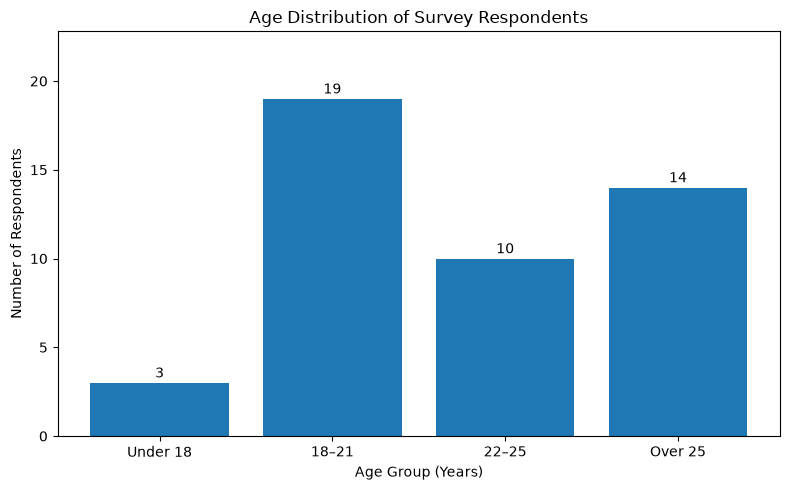

In [5]:
from pathlib import Path

Path("../figures").mkdir(parents=True, exist_ok=True)

age_order = ["<18", "18-21", "22-25", "25<"]

age_counts = df["age_group"].value_counts().reindex(
    age_order, fill_value=0
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["Under 18", "18–21", "22–25", "Over 25"],
    age_counts.values
)

ax.set_title("Age Distribution of Survey Respondents")
ax.set_xlabel("Age Group (Years)")
ax.set_ylabel("Number of Respondents")
ax.set_ylim(0, age_counts.max() * 1.2)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        int(bar.get_height()),
        ha="center"
    )

plt.tight_layout()
fig.savefig("../figures/age_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

### Year of Study Distribution

This analysis examines the academic level of survey respondents to provide context for the study population.

In [6]:
df["year_of_study"].value_counts(dropna=False)

year_of_study
3rd / Final             22
Postgrad/Masters/PhD    19
2nd                      4
NaN                      1
Name: count, dtype: int64

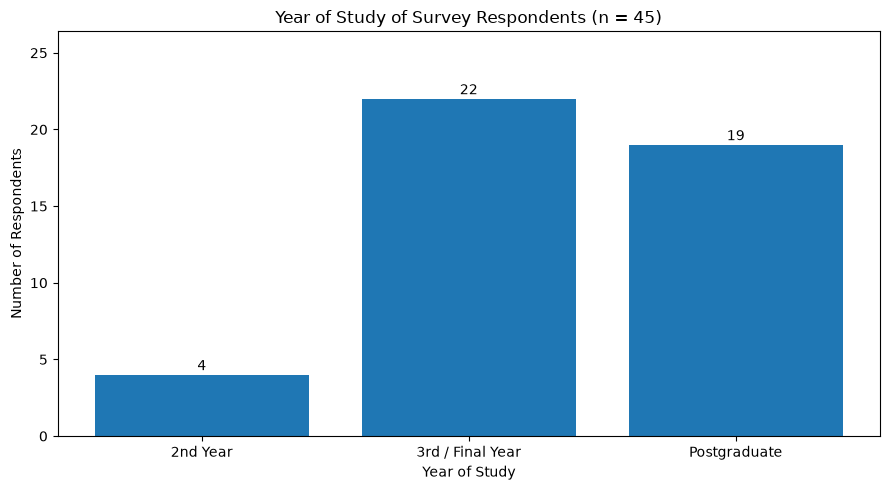

In [7]:
from pathlib import Path

Path("../figures").mkdir(parents=True, exist_ok=True)

year_order = [
    "2nd",
    "3rd / Final",
    "Postgrad/Masters/PhD"
]

year_counts = df["year_of_study"].value_counts().reindex(
    year_order, fill_value=0
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    ["2nd Year", "3rd / Final Year", "Postgraduate"],
    year_counts.values
)

ax.set_title("Year of Study of Survey Respondents (n = 45)")
ax.set_xlabel("Year of Study")
ax.set_ylabel("Number of Respondents")
ax.set_ylim(0, year_counts.max() * 1.2)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        int(bar.get_height()),
        ha="center"
    )

plt.tight_layout()

fig.savefig(
    "../figures/year_of_study.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

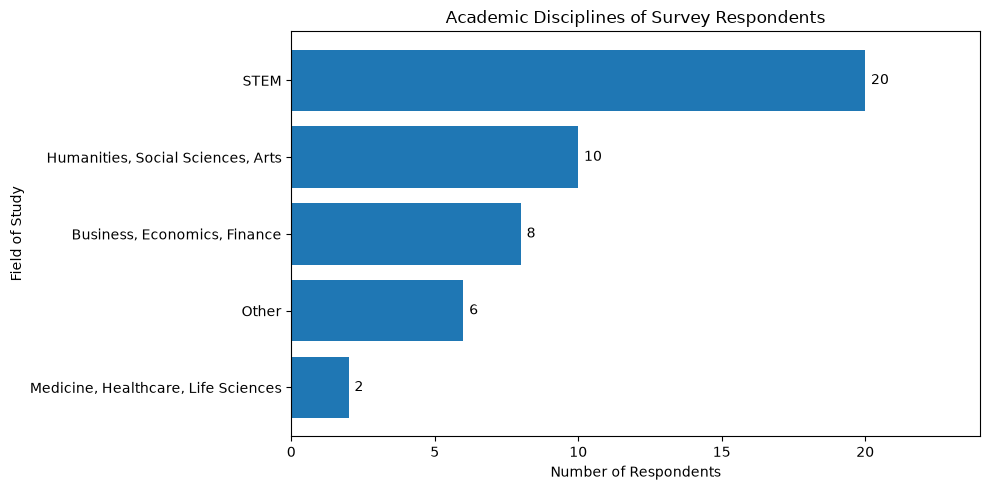

In [8]:
field_counts = df["field_of_study"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(field_counts.index, field_counts.values)

ax.set_title("Academic Disciplines of Survey Respondents")
ax.set_xlabel("Number of Respondents")
ax.set_ylabel("Field of Study")
ax.set_xlim(0, field_counts.max() * 1.2)

for bar in bars:
    ax.text(
        bar.get_width() + 0.2,
        bar.get_y() + bar.get_height() / 2,
        int(bar.get_width()),
        va="center"
    )

plt.tight_layout()

fig.savefig(
    "../figures/field_of_study.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Field of Study — Interpretation

The distribution of academic disciplines illustrates the educational backgrounds represented in the sample.

The differences between degree fields should be considered when interpreting the findings, as students from different academic disciplines may have different study demands and screen-use habits.

## 3. Sleep Habits Analysis

This section examines students' reported sleep duration, sleep quality and bedtime. These variables will subsequently be compared with productivity and academic performance to investigate possible relationships.

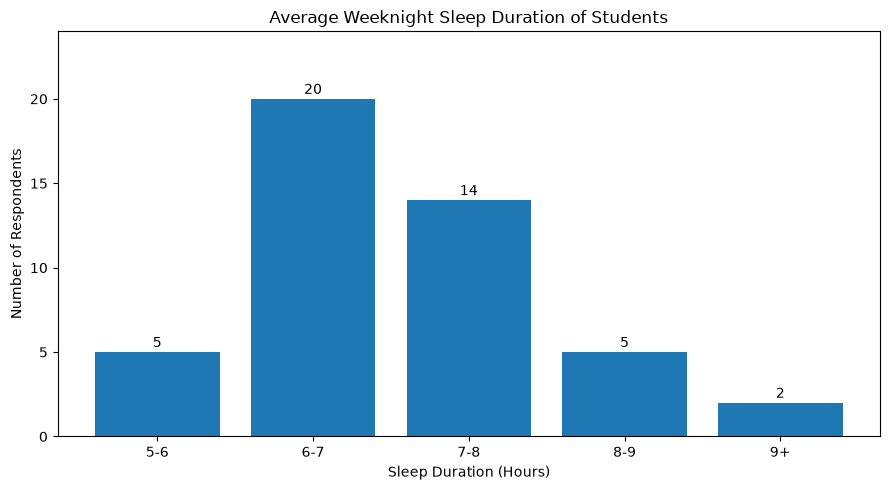

Responses shown: 46
Total responses: 46


In [9]:
sleep_order = ["5-6", "6-7", "7-8", "8-9", "9+"]

sleep_counts = df["sleep_duration"].value_counts().reindex(
    sleep_order, fill_value=0
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(sleep_counts.index, sleep_counts.values)

ax.set_title("Average Weeknight Sleep Duration of Students")
ax.set_xlabel("Sleep Duration (Hours)")
ax.set_ylabel("Number of Respondents")
ax.set_ylim(0, max(sleep_counts.max() * 1.2, 1))

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        int(bar.get_height()),
        ha="center"
    )

plt.tight_layout()
fig.savefig("../figures/sleep_duration.png", dpi=300, bbox_inches="tight")
plt.show()

print("Responses shown:", sleep_counts.sum())
print("Total responses:", len(df))

### Sleep Duration — Interpretation

The most common sleep duration was 6–7 hours, reported by 43.5% of respondents. A further 30.4% reported sleeping 7–8 hours, while only 15.2% reported sleeping more than 8 hours.

These findings indicate that sleep duration varies across the sample, with most respondents selecting the 6–7 or 7–8 hour categories.

However, sleep duration alone does not establish whether students with longer sleep report higher productivity or academic grades. These relationships will be investigated later in the analysis.

### Sleep Quality Distribution

This analysis examines respondents' self-reported sleep quality on a scale from 1 (very poor) to 10 (excellent).

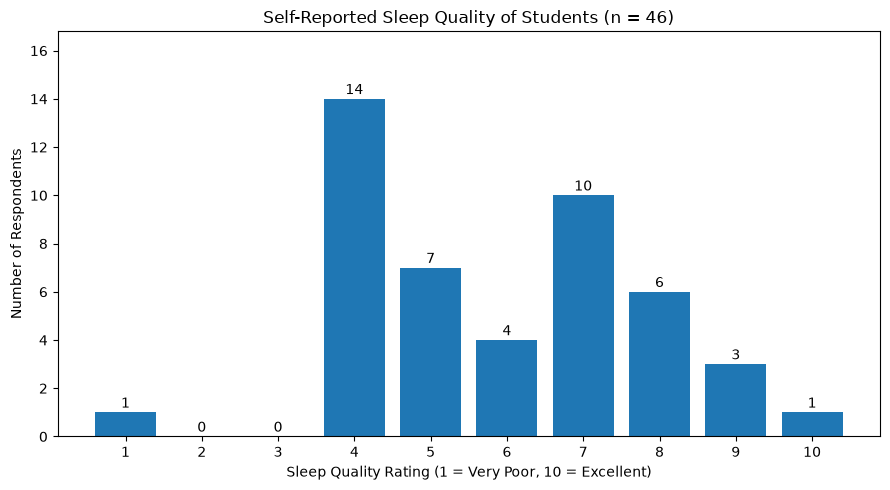

In [10]:
quality_counts = df["sleep_quality"].value_counts().reindex(
    range(1, 11), fill_value=0
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(quality_counts.index, quality_counts.values)

ax.set_title("Self-Reported Sleep Quality of Students (n = 46)")
ax.set_xlabel("Sleep Quality Rating (1 = Very Poor, 10 = Excellent)")
ax.set_ylabel("Number of Respondents")
ax.set_xticks(range(1, 11))
ax.set_ylim(0, max(quality_counts.max() * 1.2, 1))

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        int(bar.get_height()),
        ha="center"
    )

plt.tight_layout()

fig.savefig(
    "../figures/sleep_quality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Relationship Between Sleep Quality and Productivity

This analysis investigates whether students who report higher sleep quality also report higher levels of productivity.

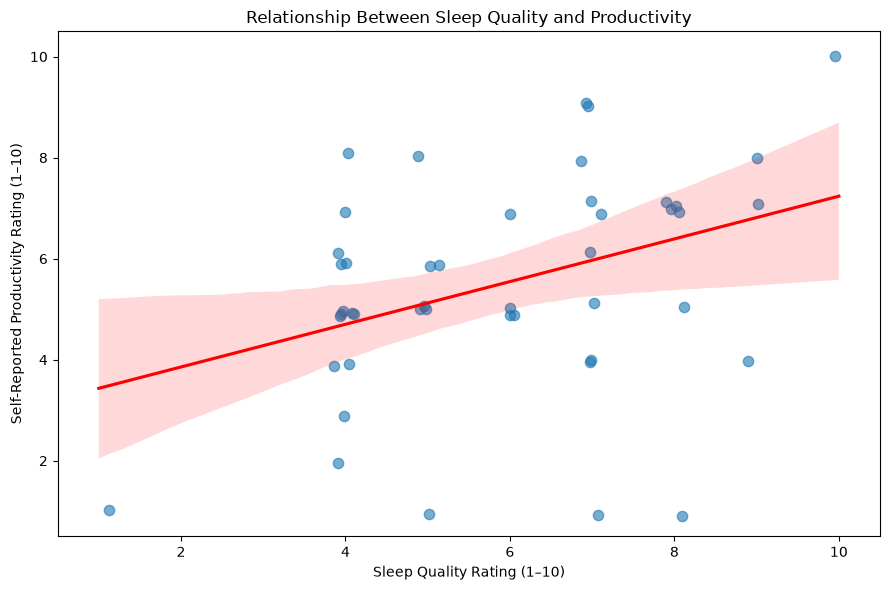

In [11]:
fig, ax = plt.subplots(figsize=(9, 6))

sns.regplot(
    data=df,
    x="sleep_quality",
    y="productivity",
    x_jitter=0.15,
    y_jitter=0.15,
    scatter_kws={"alpha": 0.6, "s": 55},
    line_kws={"color": "red"},
    ax=ax
)

ax.set_title("Relationship Between Sleep Quality and Productivity")
ax.set_xlabel("Sleep Quality Rating (1–10)")
ax.set_ylabel("Self-Reported Productivity Rating (1–10)")

ax.set_xlim(0.5, 10.5)
ax.set_ylim(0.5, 10.5)

plt.tight_layout()

fig.savefig(
    "../figures/sleep_quality_vs_productivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
correlation = df["sleep_quality"].corr(
    df["productivity"],
    method="spearman"
)

print(f"Spearman correlation: {correlation:.3f}")

Spearman correlation: 0.342


### Sleep Quality and Productivity — Interpretation

Spearman's rank correlation showed a positive association between
self-reported sleep quality and productivity (ρ = 0.342, n = 46).

This suggests that students reporting better sleep quality generally
tended to report higher productivity. However, the relationship was
not particularly strong, and the variation between individual
responses indicates that sleep quality alone does not explain
students' perceived productivity.

As both variables were self-reported and the study was observational,
the findings cannot establish causation.

### Relationship Between Sleep Duration and Productivity

This analysis compares self-reported productivity across different sleep-duration categories to investigate whether students who sleep for different lengths of time report different productivity levels.

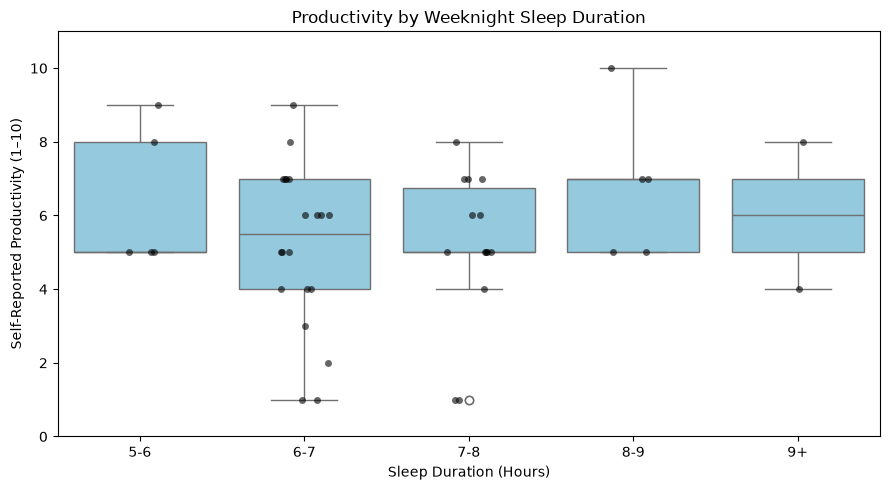

In [13]:
sleep_order = ["5-6", "6-7", "7-8", "8-9", "9+"]

fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="sleep_duration",
    y="productivity",
    order=sleep_order,
    color="skyblue",
    ax=ax
)

sns.stripplot(
    data=df,
    x="sleep_duration",
    y="productivity",
    order=sleep_order,
    color="black",
    alpha=0.6,
    jitter=0.15,
    ax=ax
)

ax.set_title("Productivity by Weeknight Sleep Duration")
ax.set_xlabel("Sleep Duration (Hours)")
ax.set_ylabel("Self-Reported Productivity (1–10)")
ax.set_ylim(0, 11)

plt.tight_layout()

fig.savefig(
    "../figures/sleep_duration_vs_productivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
sleep_summary = (
    df.groupby("sleep_duration")["productivity"]
    .agg(["count", "mean", "median", "std"])
    .reindex(sleep_order)
    .round(2)
)

sleep_summary

,count,mean,median,std
sleep_duration,,,,
5-6,5,6.40,5.0,1.95
6-7,20,5.15,5.5,2.21
7-8,14,5.14,5.0,2.07
8-9,5,6.80,7.0,2.05
9+,2,6.00,6.0,2.83


## 4. Screen Time Analysis

### Relationship Between Screen Time and Productivity

This analysis examines how students' reported daily screen time relates to their self-reported productivity scores.

In [15]:
df["screen_time"].value_counts(dropna=False)

screen_time
4 - 6 hours      17
7 - 9 hours      13
> 12  hours       7
10 - 12 hours     6
< 1 - 3 hours     3
Name: count, dtype: int64

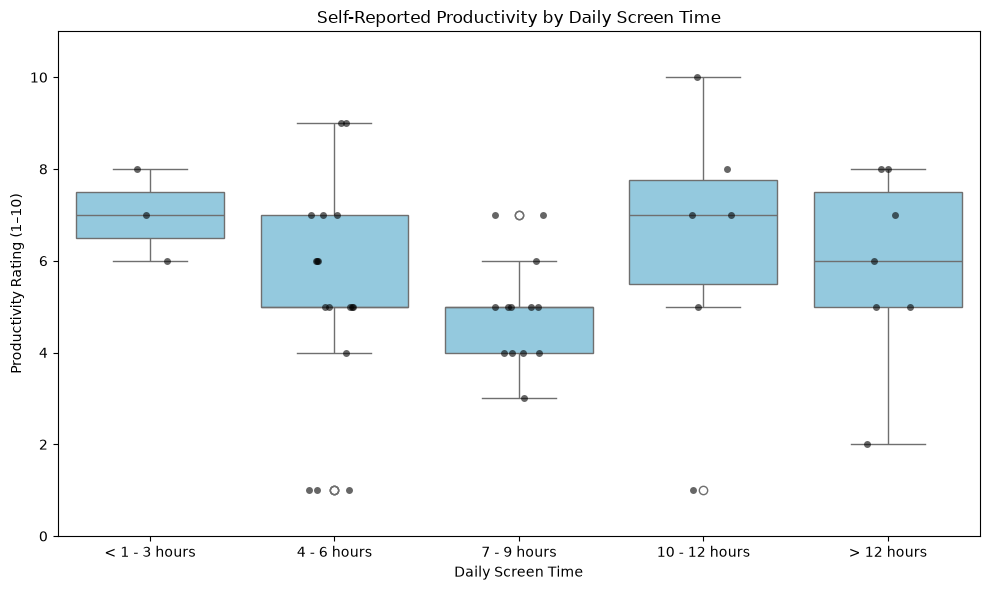

,count,mean,median,std
screen_time,,,,
< 1 - 3 hours,3,7.00,7.0,1.00
4 - 6 hours,17,5.24,5.0,2.44
7 - 9 hours,13,4.92,5.0,1.19
10 - 12 hours,6,6.33,7.0,3.08
> 12 hours,7,5.86,6.0,2.12


Responses included: 46


In [16]:
screen_order = [
    "< 1 - 3 hours",
    "4 - 6 hours",
    "7 - 9 hours",
    "10 - 12 hours",
    "> 12 hours"
]

screen_data = df[["screen_time", "productivity"]].dropna().copy()

screen_data["screen_time"] = (
    screen_data["screen_time"]
    .astype(str)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

assert set(screen_data["screen_time"]) == set(screen_order)

fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=screen_data,
    x="screen_time",
    y="productivity",
    order=screen_order,
    color="skyblue",
    ax=ax
)

sns.stripplot(
    data=screen_data,
    x="screen_time",
    y="productivity",
    order=screen_order,
    color="black",
    alpha=0.6,
    jitter=0.15,
    ax=ax
)

ax.set_title("Self-Reported Productivity by Daily Screen Time")
ax.set_xlabel("Daily Screen Time")
ax.set_ylabel("Productivity Rating (1–10)")
ax.set_ylim(0, 11)

plt.tight_layout()

fig.savefig(
    "../figures/screen_time_vs_productivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

screen_summary = (
    screen_data.groupby("screen_time")["productivity"]
    .agg(["count", "mean", "median", "std"])
    .reindex(screen_order)
    .round(2)
)

display(screen_summary)

print("Responses included:", len(screen_data))

### Screen Time and Productivity — Interpretation

The box plot shows differences in self-reported productivity across daily screen-time categories. Students reporting 7–9 hours of screen time had a median productivity score of approximately 5, while those reporting 10–12 hours had a median of approximately 7.

However, productivity did not consistently decrease as screen time increased. This suggests that total screen time alone may not adequately explain differences in students' perceived productivity.

An important limitation is that the survey measured total screen time rather than distinguishing between academic and recreational screen use. The small sample size also limits the conclusions that can be drawn, and no causal relationship can be established.

### Relationship Between Screen Time and Academic Performance

This analysis investigates how students' reported daily screen time relates to their approximate academic grades. A heatmap is used to compare the distribution of grade categories across different screen-time groups.

In [17]:
print("Screen time categories:")
print(df["screen_time"].value_counts(dropna=False))

print("\nAcademic grade categories:")
print(df["average_grade"].value_counts(dropna=False))

Screen time categories:
screen_time
4 - 6 hours      17
7 - 9 hours      13
> 12  hours       7
10 - 12 hours     6
< 1 - 3 hours     3
Name: count, dtype: int64

Academic grade categories:
average_grade
60-69    20
70-79    13
80+       7
50-59     4
NaN       2
Name: count, dtype: int64


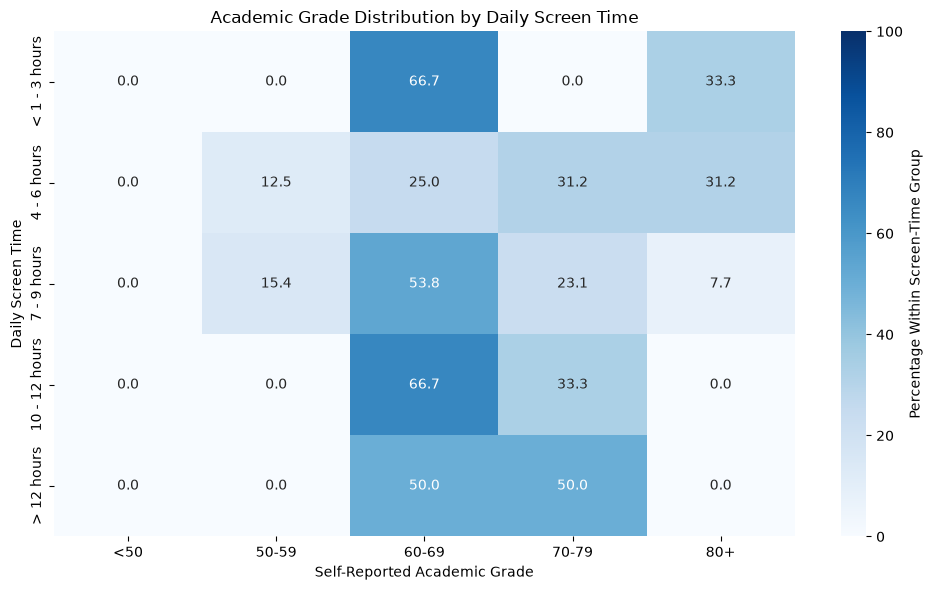

Responses included: 44

Group sizes:
screen_time
< 1 - 3 hours     3
4 - 6 hours      16
7 - 9 hours      13
10 - 12 hours     6
> 12 hours        6
dtype: int64


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

screen_order = [
    "< 1 - 3 hours",
    "4 - 6 hours",
    "7 - 9 hours",
    "10 - 12 hours",
    "> 12 hours"
]

grade_order = [
    "<50",
    "50-59",
    "60-69",
    "70-79",
    "80+"
]

grade_data = df[["screen_time", "average_grade"]].copy()

grade_data["screen_time"] = (
    grade_data["screen_time"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

grade_data["average_grade"] = (
    grade_data["average_grade"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", "", regex=True)
)

grade_data = grade_data.dropna(
    subset=["screen_time", "average_grade"]
)

grade_data["screen_time"] = grade_data["screen_time"].replace({
    "1 - 3 hours": "< 1 - 3 hours",
    "<1 - 3 hours": "< 1 - 3 hours",
    "< 1-3 hours": "< 1 - 3 hours",
    "< 1 - 3 hours": "< 1 - 3 hours",
    ">12 hours": "> 12 hours",
    "> 12 hours": "> 12 hours"
})

grade_data["average_grade"] = grade_data["average_grade"].replace({
    "80+": "80+",
    "80 +": "80+"
})

unknown_screen = set(grade_data["screen_time"]) - set(screen_order)
unknown_grades = set(grade_data["average_grade"]) - set(grade_order)

if unknown_screen or unknown_grades:
    raise ValueError(
        f"Unmatched screen categories: {unknown_screen}\n"
        f"Unmatched grade categories: {unknown_grades}"
    )

grade_counts = pd.crosstab(
    grade_data["screen_time"],
    grade_data["average_grade"]
).reindex(
    index=screen_order,
    columns=grade_order,
    fill_value=0
)

grade_percentages = (
    grade_counts.div(
        grade_counts.sum(axis=1).replace(0, float("nan")),
        axis=0
    ) * 100
)

fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    grade_percentages,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Percentage Within Screen-Time Group"},
    ax=ax
)

ax.set_title("Academic Grade Distribution by Daily Screen Time")
ax.set_xlabel("Self-Reported Academic Grade")
ax.set_ylabel("Daily Screen Time")

plt.tight_layout()

Path("../figures").mkdir(parents=True, exist_ok=True)

fig.savefig(
    "../figures/screen_time_vs_grades.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Responses included:", grade_counts.values.sum())
print("\nGroup sizes:")
print(grade_counts.sum(axis=1))

assert grade_counts.values.sum() == len(grade_data), \
    "Some valid responses were excluded from the heatmap."

### Screen Time and Academic Performance — Interpretation

The heatmap shows differences in self-reported academic grades across daily screen-time categories. Among students reporting 4–6 hours of daily screen use, 62.5% reported grades of 70% or above, compared with 30.8% among those reporting 7–9 hours.

However, the relationship is not consistent across all screen-time categories. Students reporting more than 12 hours of screen time were evenly divided between the 60–69 and 70–79 grade categories.

These findings suggest a possible association between screen time and academic performance, although small group sizes limit the strength of the conclusions. Since the data is self-reported and observational, it cannot establish a causal relationship.

### Relationship Between Sleep Duration and Academic Performance

This analysis examines how students' reported weeknight sleep duration relates to their self-reported academic grades. A 100% stacked bar chart compares the proportion of grade categories within each sleep-duration group.

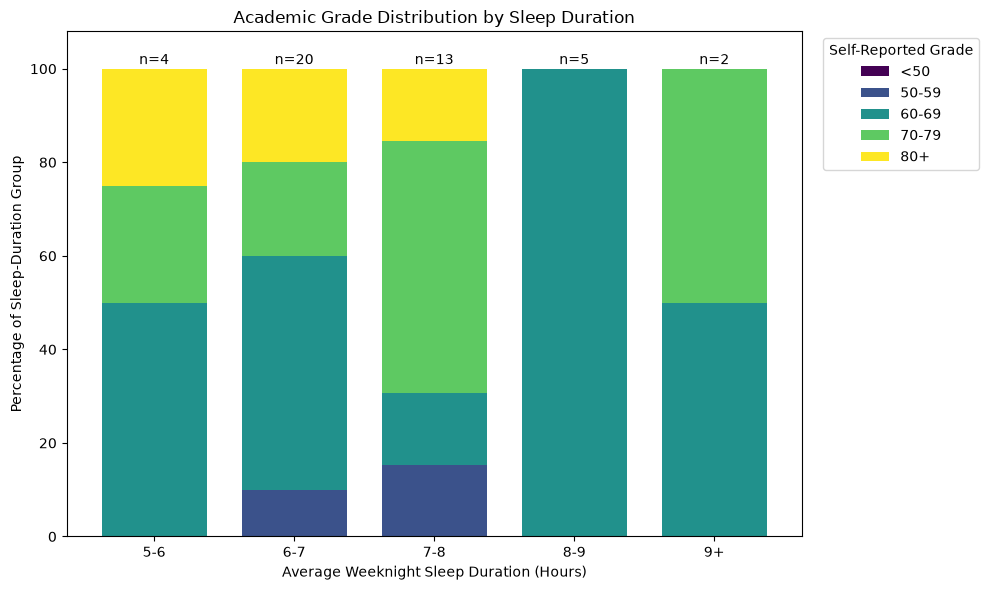

Responses included: 44

Students in each sleep-duration group:
sleep_duration
5-6     4
6-7    20
7-8    13
8-9     5
9+      2
dtype: int64


In [19]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sleep_order = ["5-6", "6-7", "7-8", "8-9", "9+"]

grade_order = ["<50", "50-59", "60-69", "70-79", "80+"]

grade_data = df[["sleep_duration", "average_grade"]].copy()

grade_data["sleep_duration"] = (
    grade_data["sleep_duration"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", "", regex=True)
)

grade_data["average_grade"] = (
    grade_data["average_grade"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", "", regex=True)
)

grade_data = grade_data.dropna()

unknown_sleep = set(grade_data["sleep_duration"]) - set(sleep_order)
unknown_grades = set(grade_data["average_grade"]) - set(grade_order)

if unknown_sleep or unknown_grades:
    raise ValueError(
        f"Unmatched sleep categories: {unknown_sleep}\n"
        f"Unmatched grade categories: {unknown_grades}"
    )

sleep_grade_counts = pd.crosstab(
    grade_data["sleep_duration"],
    grade_data["average_grade"]
).reindex(
    index=sleep_order,
    columns=grade_order,
    fill_value=0
)

assert sleep_grade_counts.to_numpy().sum() == len(grade_data), (
    "Some valid responses were excluded."
)

sleep_grade_percent = (
    sleep_grade_counts.div(
        sleep_grade_counts.sum(axis=1).replace(0, float("nan")),
        axis=0
    ) * 100
)

ax = sleep_grade_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    width=0.75,
    colormap="viridis"
)

ax.set_title("Academic Grade Distribution by Sleep Duration")
ax.set_xlabel("Average Weeknight Sleep Duration (Hours)")
ax.set_ylabel("Percentage of Sleep-Duration Group")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)

ax.legend(
    title="Self-Reported Grade",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

for i, n in enumerate(sleep_grade_counts.sum(axis=1)):
    ax.text(i, 101, f"n={n}", ha="center", fontsize=10)

ax.set_ylim(0, 108)

plt.tight_layout()

Path("../figures").mkdir(parents=True, exist_ok=True)

ax.figure.savefig(
    "../figures/sleep_duration_vs_grades.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Responses included:", sleep_grade_counts.to_numpy().sum())

print("\nStudents in each sleep-duration group:")
print(sleep_grade_counts.sum(axis=1))

### Sleep Duration and Academic Performance — Interpretation

The stacked bar chart shows differences in self-reported academic performance across sleep-duration categories. Students sleeping 7–8 hours had the highest proportion reporting grades of 70% or above (69.2%), compared with 40% among those sleeping 6–7 hours.

However, the relationship was not consistent across all categories. All five respondents sleeping 8–9 hours reported grades between 60% and 69%, while the two respondents sleeping more than nine hours reported different grade categories.

These findings suggest that sleep duration may be associated with academic performance, but there is no clear pattern of grades increasing consistently with longer sleep. The small sample sizes in several categories and the self-reported nature of the data limit the conclusions that can be drawn.

### Relationship Between Bedtime and Productivity

This analysis compares students' self-reported productivity ratings across their usual weeknight bedtime categories. The aim is to investigate whether students who go to bed at different times report different levels of productivity.

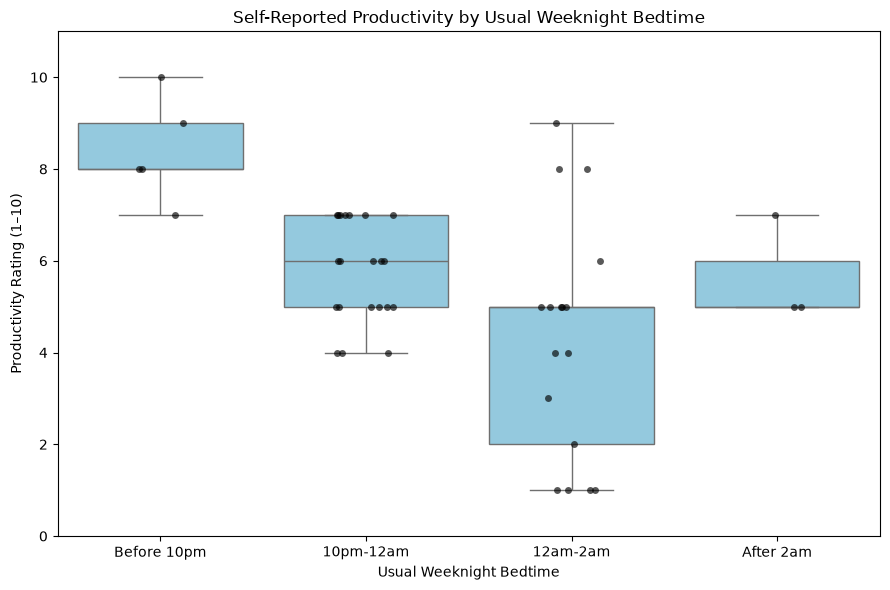

,count,mean,median,std
bedtime,,,,
Before 10pm,5,8.40,8.0,1.14
10pm-12am,21,5.76,6.0,1.09
12am-2am,17,4.29,5.0,2.57
After 2am,3,5.67,5.0,1.15


Responses included: 46


In [20]:
from pathlib import Path

bedtime_order = [
    "Before 10pm",
    "10pm-12am",
    "12am-2am",
    "After 2am"
]

bedtime_data = df[["bedtime", "productivity"]].copy()

bedtime_data["bedtime"] = (
    bedtime_data["bedtime"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", "", regex=True)
)

bedtime_data["bedtime"] = bedtime_data["bedtime"].replace({
    "Before10pm": "Before 10pm",
    "10pm-12am": "10pm-12am",
    "12am-2am": "12am-2am",
    "After2am": "After 2am"
})

bedtime_data = bedtime_data.dropna()

unmatched = set(bedtime_data["bedtime"]) - set(bedtime_order)

if unmatched:
    raise ValueError(f"Unmatched bedtime categories: {unmatched}")

fig, ax = plt.subplots(figsize=(9, 6))

sns.boxplot(
    data=bedtime_data,
    x="bedtime",
    y="productivity",
    order=bedtime_order,
    color="skyblue",
    ax=ax
)

sns.stripplot(
    data=bedtime_data,
    x="bedtime",
    y="productivity",
    order=bedtime_order,
    color="black",
    alpha=0.65,
    jitter=0.15,
    ax=ax
)

ax.set_title("Self-Reported Productivity by Usual Weeknight Bedtime")
ax.set_xlabel("Usual Weeknight Bedtime")
ax.set_ylabel("Productivity Rating (1–10)")
ax.set_ylim(0, 11)

plt.tight_layout()

Path("../figures").mkdir(parents=True, exist_ok=True)

fig.savefig(
    "../figures/bedtime_vs_productivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

bedtime_summary = (
    bedtime_data.groupby("bedtime")["productivity"]
    .agg(["count", "mean", "median", "std"])
    .reindex(bedtime_order)
    .round(2)
)

display(bedtime_summary)

print("Responses included:", bedtime_summary["count"].sum())

## 5. Productivity and Wellbeing Analysis

This section examines students' self-reported productivity, study focus, caffeine consumption and academic performance. These variables provide additional context for understanding the relationships between sleep habits, screen time and students' daily productivity.

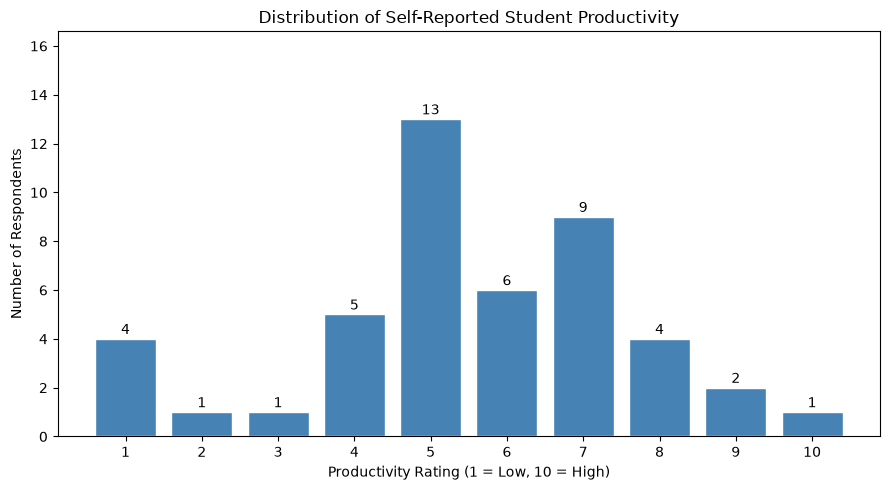

Responses included: 46
Mean productivity: 5.5
Median productivity: 5.0


In [21]:
from pathlib import Path

productivity_counts = (
    df["productivity"]
    .value_counts()
    .reindex(range(1, 11), fill_value=0)
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    productivity_counts.index,
    productivity_counts.values,
    color="steelblue",
    edgecolor="white"
)

ax.set_title("Distribution of Self-Reported Student Productivity")
ax.set_xlabel("Productivity Rating (1 = Low, 10 = High)")
ax.set_ylabel("Number of Respondents")
ax.set_xticks(range(1, 11))
ax.set_ylim(0, productivity_counts.max() * 1.2 + 1)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        int(bar.get_height()),
        ha="center"
    )

plt.tight_layout()

Path("../figures").mkdir(parents=True, exist_ok=True)

fig.savefig(
    "../figures/productivity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Responses included:", productivity_counts.sum())
print("Mean productivity:", round(df["productivity"].mean(), 2))
print("Median productivity:", df["productivity"].median())

### Productivity Distribution — Interpretation

Students reported an average productivity rating of 5.50 out of 10, with a median score of 5. Ratings ranged from 1 to 10, demonstrating variation in perceived productivity across respondents.

These results suggest that productivity levels differ considerably within the sample. However, productivity is measured through self-reported perceptions rather than an objective assessment of completed work.

Further comparisons with sleep and screen-time variables are therefore necessary to investigate potential relationships.

### Study Focus and Caffeine Consumption

This analysis examines the number of hours students report staying focused while studying or working, alongside their caffeine consumption frequency. These variables provide additional context for understanding students' self-reported productivity and wellbeing.

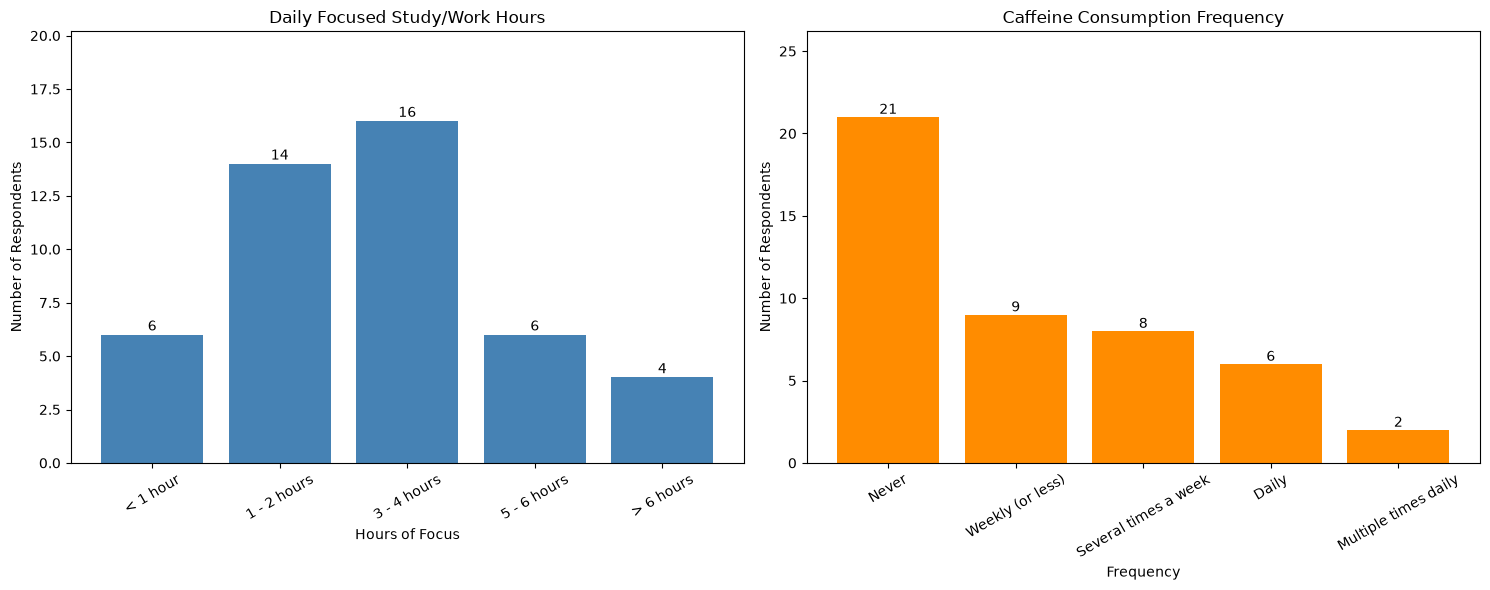

Focus responses included: 46
Caffeine responses included: 46

Focus hour distribution:
focus_hours
< 1 hour        6
1 - 2 hours    14
3 - 4 hours    16
5 - 6 hours     6
> 6 hours       4
Name: count, dtype: Int64

Caffeine consumption distribution:
caffeine
Never                   21
Weekly (or less)         9
Several times a week     8
Daily                    6
Multiple times daily     2
Name: count, dtype: Int64


In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

focus_order = [
    "< 1 hour",
    "1 - 2 hours",
    "3 - 4 hours",
    "5 - 6 hours",
    "> 6 hours"
]

caffeine_order = [
    "Never",
    "Weekly (or less)",
    "Several times a week",
    "Daily",
    "Multiple times daily"
]

focus_data = (
    df["focus_hours"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

caffeine_data = (
    df["caffeine"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

unknown_focus = set(focus_data.dropna()) - set(focus_order)
unknown_caffeine = set(caffeine_data.dropna()) - set(caffeine_order)

if unknown_focus or unknown_caffeine:
    raise ValueError(
        f"Unmatched focus categories: {unknown_focus}\n"
        f"Unmatched caffeine categories: {unknown_caffeine}"
    )

focus_counts = focus_data.value_counts().reindex(
    focus_order, fill_value=0
)

caffeine_counts = caffeine_data.value_counts().reindex(
    caffeine_order, fill_value=0
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

bars1 = axes[0].bar(
    focus_counts.index,
    focus_counts.values,
    color="steelblue"
)

axes[0].set_title("Daily Focused Study/Work Hours")
axes[0].set_xlabel("Hours of Focus")
axes[0].set_ylabel("Number of Respondents")
axes[0].tick_params(axis="x", rotation=30)

bars2 = axes[1].bar(
    caffeine_counts.index,
    caffeine_counts.values,
    color="darkorange"
)

axes[1].set_title("Caffeine Consumption Frequency")
axes[1].set_xlabel("Frequency")
axes[1].set_ylabel("Number of Respondents")
axes[1].tick_params(axis="x", rotation=30)

for ax, bars in zip(axes, [bars1, bars2]):
    ax.set_ylim(0, max(bar.get_height() for bar in bars) * 1.2 + 1)

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.2,
            int(bar.get_height()),
            ha="center"
        )

plt.tight_layout()

Path("../figures").mkdir(parents=True, exist_ok=True)

fig.savefig(
    "../figures/focus_and_caffeine.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Focus responses included:", focus_counts.sum())
print("Caffeine responses included:", caffeine_counts.sum())

print("\nFocus hour distribution:")
print(focus_counts)

print("\nCaffeine consumption distribution:")
print(caffeine_counts)

### Study Focus and Caffeine Consumption — Interpretation

The most common focused study duration was 3–4 hours per day (34.8%), followed by 1–2 hours (30.4%). Together, these categories accounted for 65.2% of respondents, indicating that most students reported between one and four hours of focused work or study.

Regarding caffeine consumption, 45.7% reported never using caffeine to stay alert, while 17.4% reported consuming it daily or multiple times daily.

These findings provide context for students' study habits and wellbeing. However, the distributions alone do not establish whether caffeine consumption influences productivity or academic performance.

### Screen Distractions

This analysis examines how frequently students report that screen use distracts them from completing tasks. It provides additional context for understanding the relationship between screen habits and self-reported productivity.

In [23]:
df["screen_distraction"].value_counts(dropna=False)

screen_distraction
Often           18
Occasionally    13
Always           9
Rarely           6
Name: count, dtype: int64

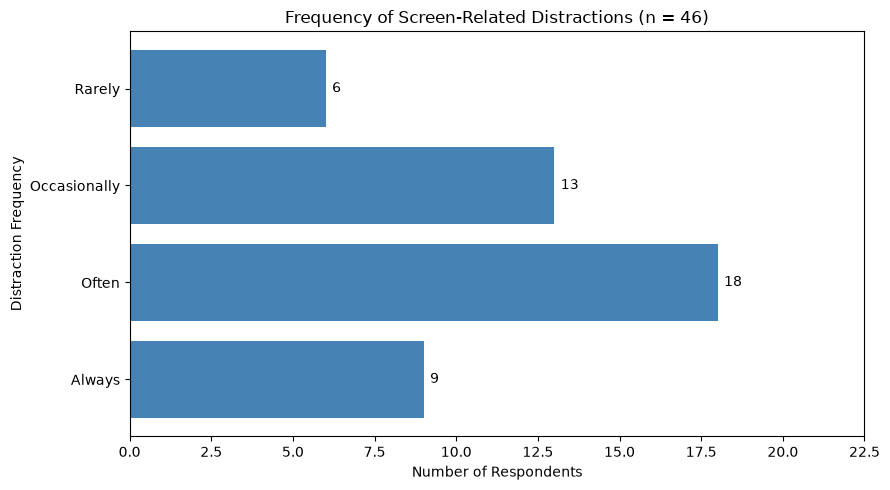

Responses included: 46


In [24]:
from pathlib import Path
import matplotlib.pyplot as plt

distraction_order = [
    "Rarely",
    "Occasionally",
    "Often",
    "Always"
]

distraction_counts = (
    df["screen_distraction"]
    .value_counts()
    .reindex(distraction_order, fill_value=0)
)

assert distraction_counts.sum() == len(df)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    distraction_counts.index,
    distraction_counts.values,
    color="steelblue"
)

ax.set_title("Frequency of Screen-Related Distractions (n = 46)")
ax.set_xlabel("Number of Respondents")
ax.set_ylabel("Distraction Frequency")
ax.set_xlim(0, distraction_counts.max() * 1.25)

for bar in bars:
    ax.text(
        bar.get_width() + 0.2,
        bar.get_y() + bar.get_height() / 2,
        str(int(bar.get_width())),
        va="center"
    )

ax.invert_yaxis()

plt.tight_layout()

Path("../figures").mkdir(parents=True, exist_ok=True)

fig.savefig(
    "../figures/screen_distractions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Responses included:", distraction_counts.sum())

### Relationship Between Screen Distractions and Productivity

This analysis compares students' self-reported productivity ratings across different levels of screen-related distraction. A box plot is used to examine differences in productivity scores between the groups.

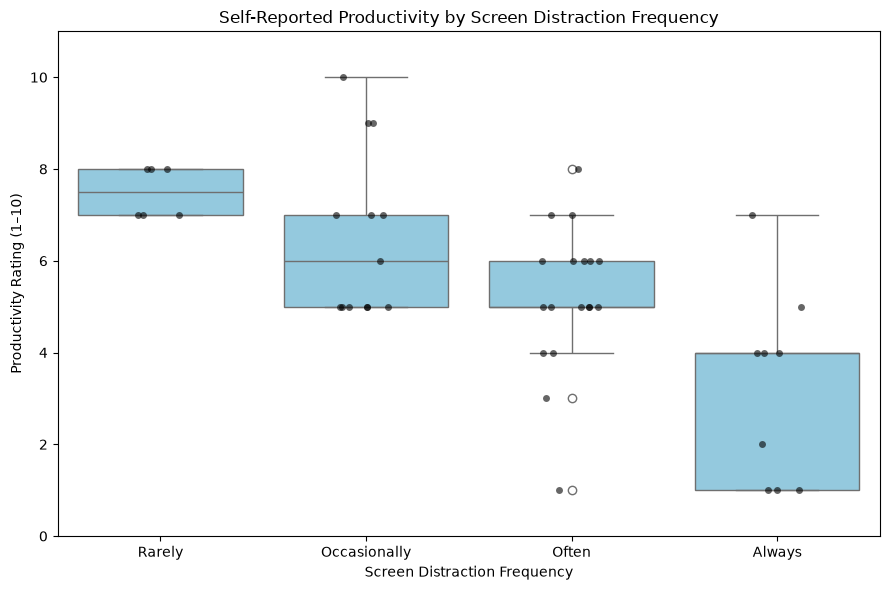

,count,mean,median,std
screen_distraction,,,,
Rarely,6,7.50,7.5,0.55
Occasionally,13,6.54,6.0,1.81
Often,18,5.22,5.0,1.59
Always,9,3.22,4.0,2.11


Responses included: 46


In [25]:
from pathlib import Path

distraction_order = [
    "Rarely",
    "Occasionally",
    "Often",
    "Always"
]

distraction_data = df[
    ["screen_distraction", "productivity"]
].dropna().copy()

fig, ax = plt.subplots(figsize=(9, 6))

sns.boxplot(
    data=distraction_data,
    x="screen_distraction",
    y="productivity",
    order=distraction_order,
    color="skyblue",
    ax=ax
)

sns.stripplot(
    data=distraction_data,
    x="screen_distraction",
    y="productivity",
    order=distraction_order,
    color="black",
    alpha=0.6,
    jitter=0.15,
    ax=ax
)

ax.set_title("Self-Reported Productivity by Screen Distraction Frequency")
ax.set_xlabel("Screen Distraction Frequency")
ax.set_ylabel("Productivity Rating (1–10)")
ax.set_ylim(0, 11)

plt.tight_layout()

Path("../figures").mkdir(parents=True, exist_ok=True)

fig.savefig(
    "../figures/screen_distraction_vs_productivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

distraction_summary = (
    distraction_data.groupby("screen_distraction")["productivity"]
    .agg(["count", "mean", "median", "std"])
    .reindex(distraction_order)
    .round(2)
)

display(distraction_summary)

print("Responses included:", len(distraction_data))

### Screen Distractions and Productivity — Interpretation

The box plot indicates a negative association between screen-distraction frequency and self-reported productivity. Students who rarely experienced distractions had the highest median productivity rating (7.5), compared with 6 among those occasionally distracted, 5 among those often distracted and 4 among those always distracted.

Although individual productivity scores varied within the groups, the overall pattern suggests that students reporting more frequent screen distractions tended to report lower productivity.

However, these findings cannot establish causation, as both distraction frequency and productivity were self-reported. Other factors, including workload, sleep habits and study environment, may also influence these ratings.

In [26]:
df.groupby("screen_distraction")["productivity"].agg(
    ["count", "mean", "median"]
).reindex(["Rarely", "Occasionally", "Often", "Always"]).round(2)

,count,mean,median
screen_distraction,,,
Rarely,6,7.50,7.5
Occasionally,13,6.54,6.0
Often,18,5.22,5.0
Always,9,3.22,4.0


### Qualitative Analysis of Factors Affecting Productivity

This section examines students' written responses about factors affecting their productivity. Responses will be reviewed and grouped into themes to identify common factors that may help explain patterns observed in the quantitative analysis.

In [27]:
responses = df["productivity_factor"].dropna().astype(str).str.strip()

responses = responses[responses != ""]

print("Number of written responses:", len(responses))
print("Number of missing or blank responses:", len(df) - len(responses))

for number, response in enumerate(responses, start=1):
    print(f"{number}. {response}")

Number of written responses: 34
Number of missing or blank responses: 12
1. procrastinating
2. Doomscrolling
3. Grades
4. Checking my phone every few mins
5. Adhd
6. procrastination
7. The dopamine rush triggered by social media usage
8. Waking hours
9. How I slept, mood, if I like what I’m working on
10. Music
11. Phone notifications distracting
12. Dw
13. Conversation
14. Procrastination
15. Apps notifications
16. Doomscrolling
17. fatigue
18. maybe environment
19. Environment
20. Phone
21. Lack of motivation
22. My phone 😓
23. Tiredness
24. Tiredness.
25. How much sleep i got the night before
26. Electronics
27. Devices
28. Messages
29. Procrastinating
30. Poor focus and not having motivation
31. Browsing through social media and gaming
32. Distractions
33. Phone
34. Self drive but mostly from distractions from watching videos


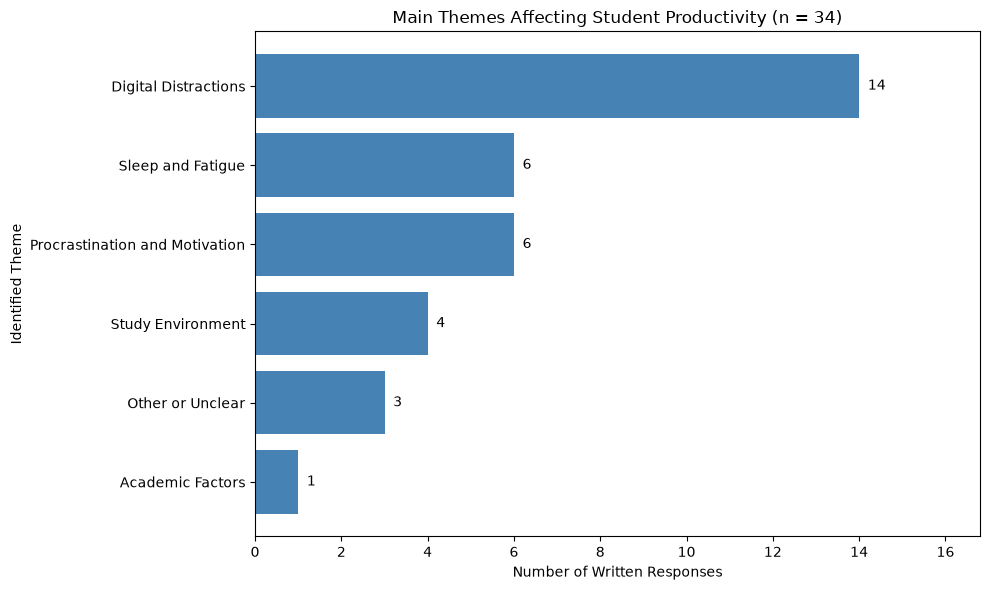

Responses analysed: 34

Theme counts:
theme
Digital Distractions              14
Procrastination and Motivation     6
Sleep and Fatigue                  6
Study Environment                  4
Other or Unclear                   3
Academic Factors                   1
Name: count, dtype: int64


,response,theme
0,procrastinating,Procrastination and Motivation
1,Doomscrolling,Digital Distractions
2,Grades,Academic Factors
3,Checking my phone every few mins,Digital Distractions
4,Adhd,Other or Unclear
5,procrastination,Procrastination and Motivation
6,The dopamine rush triggered by social media usage,Digital Distractions
7,Waking hours,Sleep and Fatigue
8,"How I slept, mood, if I like what I’m working on",Sleep and Fatigue
9,Music,Study Environment


In [28]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

themes = {
    1: "Procrastination and Motivation",
    2: "Digital Distractions",
    3: "Academic Factors",
    4: "Digital Distractions",
    5: "Other or Unclear",
    6: "Procrastination and Motivation",
    7: "Digital Distractions",
    8: "Sleep and Fatigue",
    9: "Sleep and Fatigue",
    10: "Study Environment",
    11: "Digital Distractions",
    12: "Other or Unclear",
    13: "Study Environment",
    14: "Procrastination and Motivation",
    15: "Digital Distractions",
    16: "Digital Distractions",
    17: "Sleep and Fatigue",
    18: "Study Environment",
    19: "Study Environment",
    20: "Digital Distractions",
    21: "Procrastination and Motivation",
    22: "Digital Distractions",
    23: "Sleep and Fatigue",
    24: "Sleep and Fatigue",
    25: "Sleep and Fatigue",
    26: "Digital Distractions",
    27: "Digital Distractions",
    28: "Digital Distractions",
    29: "Procrastination and Motivation",
    30: "Procrastination and Motivation",
    31: "Digital Distractions",
    32: "Other or Unclear",
    33: "Digital Distractions",
    34: "Digital Distractions"
}

responses = (
    df["productivity_factor"]
    .dropna()
    .astype(str)
    .str.strip()
)

responses = responses[responses != ""]

assert len(responses) == 34
assert len(themes) == len(responses)

qualitative_df = pd.DataFrame({
    "response": responses.values,
    "theme": [themes[i] for i in range(1, len(responses) + 1)]
})

theme_counts = (
    qualitative_df["theme"]
    .value_counts()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    theme_counts.index,
    theme_counts.values,
    color="steelblue"
)

ax.set_title("Main Themes Affecting Student Productivity (n = 34)")
ax.set_xlabel("Number of Written Responses")
ax.set_ylabel("Identified Theme")
ax.set_xlim(0, theme_counts.max() * 1.2)

for bar in bars:
    ax.text(
        bar.get_width() + 0.2,
        bar.get_y() + bar.get_height() / 2,
        int(bar.get_width()),
        va="center"
    )

plt.tight_layout()

Path("../figures").mkdir(parents=True, exist_ok=True)

fig.savefig(
    "../figures/productivity_themes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Responses analysed:", len(qualitative_df))
print("\nTheme counts:")
print(qualitative_df["theme"].value_counts())

display(qualitative_df)

### Qualitative Coding Method

Of the 46 respondents, 34 provided an answer to the open-text question about factors affecting productivity.

Responses were reviewed and assigned to one primary theme based on their main stated factor. Six categories were used: digital distractions, procrastination and motivation, sleep and fatigue, study environment, academic pressure, and other or unclear.

Some responses mentioned multiple factors, so assigning one primary theme involved interpretation. The classifications were reviewed against the original answers before calculating theme frequencies.

The findings should be interpreted as exploratory because the sample was relatively small and the categories were developed from the survey responses.

### Qualitative Findings — Interpretation

Digital distractions were the most frequently identified factor affecting productivity, appearing in 14 of the 34 written responses (41.2%). Procrastination and motivation, alongside sleep and fatigue, were each identified in six responses (17.6%).

These findings complement the quantitative results, particularly the relationship between screen-distraction frequency and self-reported productivity.

However, the themes were based on brief written responses, and some answers could reasonably fit multiple categories. The classifications therefore involve subjective judgement and should be interpreted cautiously.